# Modern English to Shakespearean English Translation using Transformers

## 📌 Project Overview

This project builds a **Transformer Encoder-Decoder model** that converts modern English sentences into Shakespearean-style English.

The model learns the transformation purely from example sentence pairs provided in the dataset. Unlike rule-based systems, the model learns vocabulary patterns, word relationships, and sequence transformations using **Multi-Head Attention**.

### Example

| Modern English | Shakespearean English |
|---|---|
| you are my friend | thou art my companion |
| it is very beautiful here | 'tis most fair hither |
| she has a brave enemy | she hath a valiant foe |
| perhaps you will help | perchance thou shall aid |
| goodbye my old friend | farewell my aged companion |

---

## 🎯 Objective

Build a word-level Transformer Encoder-Decoder model that:

- Learns from modern/Shakespearean sentence pairs
- Uses a shared word-level vocabulary
- Uses Multi-Head Attention
- Uses positional encoding
- Uses an Encoder-Decoder Transformer architecture
- Uses a causal mask during decoding
- Uses greedy decoding during inference
- Provides a `predict()` function for new sentences

---

## 🧠 Model Architecture

```text
Modern English Sentence
        │
        ▼
Word Tokenization
        │
        ▼
Shared Vocabulary
        │
        ▼
Token Embedding
        │
        ▼
Positional Encoding
        │
        ▼
Transformer Encoder
        │
        │ Context / Memory
        ▼
Transformer Decoder
        │
        │ Multi-Head Attention
        ▼
Linear Projection
        │
        ▼
Greedy Decoding
        │
        ▼
Shakespearean English Sentence

🔑 Key Components

* Tokenization: Word-level tokenization using split()
* Vocabulary: Shared vocabulary for both languages
* <pad>: 0
* <sos>: 1
* <eos>: 2
* <unk>: 3
* Embedding Dimension: 256
* Attention Heads: 8
* Encoder Layers: 3
* Decoder Layers: 3
* Loss: Cross Entropy Loss
* Optimizer: Adam
* Decoding: Greedy decoding

📊 Dataset

File: shakespeare_dataset.csv

Columns:

* modern
* shakespearean

The dataset contains approximately 15,000 sentence pairs, with sentence lengths ranging from approximately 3–10 words.

In [3]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

import pandas as pd
import numpy as np

import math
import random
import urllib.request

from collections import Counter

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

from sklearn.model_selection import train_test_split


# ============================================================
# RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


# ============================================================
# DEVICE
# ============================================================
# MacBook Air M4 uses Apple's MPS backend for GPU acceleration.
# CUDA is for NVIDIA GPUs and is not available on Apple Silicon.

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")


print("PyTorch Version:", torch.__version__)
print("Device:", device)


# ============================================================
# DEVICE INFORMATION
# ============================================================

if device.type == "mps":
    print("Apple Silicon GPU: MPS")
    print("Using MacBook GPU acceleration")

elif device.type == "cuda":
    print("NVIDIA GPU:", torch.cuda.get_device_name(0))

else:
    print("Using CPU")

PyTorch Version: 2.14.0
Device: mps
Apple Silicon GPU: MPS
Using MacBook GPU acceleration


## 1. Dataset Loading

The dataset contains pairs of equivalent sentences:

- `modern` → Modern English sentence
- `shakespearean` → Shakespearean-style equivalent

The dataset is downloaded directly from the provided source URL and loaded using Pandas.

In [4]:
# ============================================================
# DOWNLOAD DATASET
# ============================================================

url = "https://s3.ap-south-1.amazonaws.com/new-assets.ccbp.in/frontend/content/aiml/shakespeare_dataset.csv"

urllib.request.urlretrieve(
    url,
    "shakespeare_dataset.csv"
)


# ============================================================
# LOAD DATASET
# ============================================================

df = pd.read_csv(
    "shakespeare_dataset.csv",
    dtype=str
)


# ============================================================
# BASIC CLEANING
# ============================================================

df = df.dropna(
    subset=["modern", "shakespearean"]
).reset_index(drop=True)

df["modern"] = df["modern"].str.strip()
df["shakespearean"] = df["shakespearean"].str.strip()

df = df[
    (df["modern"] != "") &
    (df["shakespearean"] != "")
].reset_index(drop=True)


# ============================================================
# DATASET INFORMATION
# ============================================================

print("Dataset Shape:", df.shape)

display(df.head(10))

Dataset Shape: (15137, 2)


,modern,shakespearean
0,it is dark to fear the kingdom,'tis shadowed to dread the realm
1,she is perhaps strange,she is perchance peculiar
2,my friend has a tired spirit,my companion hath a weary soul
3,where i will give the friend,whither i will bestow the companion
4,they must fear the honor,they must dread the honor
5,my brother is beautiful soon,my brother is fair soon
6,they will find the spirit,they will find the soul
7,the queen will ask the spirit,the queen will inquire the soul
8,here the queen will think the kingdom,hither the queen will ponder the realm
9,you are strange and you will stop the spirit,thou art peculiar and thou shall cease the soul


## 2. Exploratory Data Analysis

Before building the Transformer, we inspect:

- Number of sentence pairs
- Dataset columns
- Sentence lengths
- Example transformations

Sentence lengths are measured using word-level tokenization because the assignment requires space-based tokenization.

In [5]:
# ============================================================
# SENTENCE LENGTH ANALYSIS
# ============================================================

df["modern_length"] = df["modern"].apply(
    lambda x: len(x.split())
)

df["shakespearean_length"] = df["shakespearean"].apply(
    lambda x: len(x.split())
)


print("Number of sentence pairs:", len(df))

print(
    "\nModern sentence length:"
)

print(
    df["modern_length"].describe()
)

print(
    "\nShakespearean sentence length:"
)

print(
    df["shakespearean_length"].describe()
)


# ============================================================
# EXAMPLES
# ============================================================

display(
    df[
        [
            "modern",
            "shakespearean",
            "modern_length",
            "shakespearean_length"
        ]
    ].head(10)
)

Number of sentence pairs: 15137

Modern sentence length:
count    15137.000000
mean         5.568409
std          1.124204
min          3.000000
25%          5.000000
50%          5.000000
75%          6.000000
max          9.000000
Name: modern_length, dtype: float64

Shakespearean sentence length:
count    15137.000000
mean         5.506771
std          1.070134
min          3.000000
25%          5.000000
50%          5.000000
75%          6.000000
max          9.000000
Name: shakespearean_length, dtype: float64


,modern,shakespearean,modern_length,shakespearean_length
0,it is dark to fear the kingdom,'tis shadowed to dread the realm,7,6
1,she is perhaps strange,she is perchance peculiar,4,4
2,my friend has a tired spirit,my companion hath a weary soul,6,6
3,where i will give the friend,whither i will bestow the companion,6,6
4,they must fear the honor,they must dread the honor,5,5
5,my brother is beautiful soon,my brother is fair soon,5,5
6,they will find the spirit,they will find the soul,5,5
7,the queen will ask the spirit,the queen will inquire the soul,6,6
8,here the queen will think the kingdom,hither the queen will ponder the realm,7,7
9,you are strange and you will stop the spirit,thou art peculiar and thou shall cease the soul,9,9


## 3. Train-Test Split

The dataset is divided into:

- **90% Training Data**
- **10% Testing Data**

The training data is used to learn the transformation from modern English to Shakespearean English.

The test data is kept separate for evaluating the model's ability to generalize to unseen sentence pairs.

In [6]:
# ============================================================
# TRAIN-TEST SPLIT
# ============================================================

train_df, test_df = train_test_split(
    df,
    test_size=0.10,
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Testing samples :", len(test_df))

Training samples: 13623
Testing samples : 1514


## 4. Vocabulary Construction

A **shared vocabulary** is created using words from both the modern English and Shakespearean English sentences.

The assignment requires the following special token indices:

| Token | Index | Purpose |
|---|---:|---|
| `<pad>` | 0 | Padding sequences |
| `<sos>` | 1 | Start of sentence |
| `<eos>` | 2 | End of sentence |
| `<unk>` | 3 | Unknown words |

Every sentence is converted into a sequence of integer indices.

### Example

```text
you are my friend

In [7]:
# 💻 Cell 10 — Code
# ============================================================
# SPECIAL TOKENS
# ============================================================

PAD_IDX = 0
SOS_IDX = 1
EOS_IDX = 2
UNK_IDX = 3


SPECIAL_TOKENS = {
    "<pad>": PAD_IDX,
    "<sos>": SOS_IDX,
    "<eos>": EOS_IDX,
    "<unk>": UNK_IDX
}


# ============================================================
# BUILD SHARED VOCABULARY
# ============================================================

counter = Counter()


# Words from modern English
for sentence in df["modern"]:
    counter.update(sentence.split())


# Words from Shakespearean English
for sentence in df["shakespearean"]:
    counter.update(sentence.split())


# Initialize vocabulary with special tokens
vocab = {
    "<pad>": PAD_IDX,
    "<sos>": SOS_IDX,
    "<eos>": EOS_IDX,
    "<unk>": UNK_IDX
}


# Add words
for word in counter:

    if word not in vocab:
        vocab[word] = len(vocab)


# Reverse vocabulary
idx_to_word = {
    idx: word
    for word, idx in vocab.items()
}


vocab_size = len(vocab)


print("Vocabulary Size:", vocab_size)

print(
    "\nSpecial Tokens:"
)

print(SPECIAL_TOKENS)

Vocabulary Size: 159

Special Tokens:
{'<pad>': 0, '<sos>': 1, '<eos>': 2, '<unk>': 3}


## 5. Sentence Encoding

Each sentence is converted into token IDs.

The `<sos>` and `<eos>` tokens are added to every sequence.

Unknown words are mapped to `<unk>`.

This allows the Transformer to process sentences numerically.

In [8]:
# ============================================================
# ENCODE SENTENCE
# ============================================================

def encode_sentence(sentence):

    tokens = sentence.split()

    encoded = [SOS_IDX]

    for token in tokens:

        encoded.append(
            vocab.get(
                token,
                UNK_IDX
            )
        )

    encoded.append(EOS_IDX)

    return encoded


# ============================================================
# TEST ENCODING
# ============================================================

example = "you are my friend"

encoded_example = encode_sentence(example)

print("Sentence:")
print(example)

print("\nEncoded:")
print(encoded_example)

Sentence:
you are my friend

Encoded:
[1, 35, 36, 14, 15, 2]


## 6. PyTorch Dataset and DataLoader

The custom PyTorch Dataset stores:

- Modern English sentences as source sequences
- Shakespearean sentences as target sequences

Because sentences have different lengths, sequences are padded within each batch using `<pad>` with index `0`.

Padding is ignored during loss calculation.

In [9]:
# ============================================================
# DATASET
# ============================================================

class ShakespeareDataset(Dataset):

    def __init__(self, dataframe):

        self.modern = dataframe["modern"].tolist()
        self.shakespearean = dataframe["shakespearean"].tolist()

    def __len__(self):

        return len(self.modern)

    def __getitem__(self, idx):

        src = torch.tensor(
            encode_sentence(
                self.modern[idx]
            ),
            dtype=torch.long
        )

        tgt = torch.tensor(
            encode_sentence(
                self.shakespearean[idx]
            ),
            dtype=torch.long
        )

        return src, tgt


# ============================================================
# COLLATE FUNCTION
# ============================================================

def collate_fn(batch):

    src_batch = []
    tgt_batch = []

    for src, tgt in batch:

        src_batch.append(src)
        tgt_batch.append(tgt)

    src_batch = pad_sequence(
        src_batch,
        batch_first=True,
        padding_value=PAD_IDX
    )

    tgt_batch = pad_sequence(
        tgt_batch,
        batch_first=True,
        padding_value=PAD_IDX
    )

    return src_batch, tgt_batch


# ============================================================
# CREATE DATASETS
# ============================================================

train_dataset = ShakespeareDataset(
    train_df
)

test_dataset = ShakespeareDataset(
    test_df
)


# ============================================================
# CREATE DATALOADERS
# ============================================================

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)


# ============================================================
# CHECK BATCH
# ============================================================

src, tgt = next(
    iter(train_loader)
)

print("Source batch shape:", src.shape)
print("Target batch shape:", tgt.shape)

Source batch shape: torch.Size([64, 11])
Target batch shape: torch.Size([64, 11])


## 7. Positional Encoding

Transformers do not inherently know the order of words in a sentence.

Positional encoding provides information about the position of each token.

The positional encoding is added to the token embeddings before they are passed into the Transformer Encoder and Decoder.

In [10]:
# ============================================================
# POSITIONAL ENCODING
# ============================================================

class PositionalEncoding(nn.Module):

    def __init__(
        self,
        d_model,
        max_len=100
    ):

        super().__init__()

        pe = torch.zeros(
            max_len,
            d_model
        )

        position = torch.arange(
            0,
            max_len,
            dtype=torch.float
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(
                0,
                d_model,
                2
            ).float()
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(
            position * div_term
        )

        pe[:, 1::2] = torch.cos(
            position * div_term
        )

        pe = pe.unsqueeze(0)

        self.register_buffer(
            "pe",
            pe
        )


    def forward(self, x):

        return x + self.pe[:, :x.size(1)]

## 8. Transformer Encoder-Decoder Architecture

The model uses a standard Transformer Encoder-Decoder architecture.

### Encoder

The encoder reads the complete modern English sentence and creates a contextual representation.

### Decoder

The decoder generates the Shakespearean sentence one token at a time.

### Multi-Head Attention

The Transformer uses multiple attention heads to learn relationships between words.

### Causal Mask

A causal/look-ahead mask prevents the decoder from seeing future target tokens during training.

This ensures that the model learns autoregressive generation.

In [11]:
# ============================================================
# TRANSFORMER MODEL
# ============================================================

class TransformerModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        d_model=256,
        nhead=8,
        num_encoder_layers=3,
        num_decoder_layers=3,
        dim_feedforward=512,
        dropout=0.1
    ):

        super().__init__()

        self.d_model = d_model

        # ----------------------------------------------------
        # Token Embedding
        # ----------------------------------------------------

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=PAD_IDX
        )


        # ----------------------------------------------------
        # Positional Encoding
        # ----------------------------------------------------

        self.positional_encoding = PositionalEncoding(
            d_model,
            max_len=100
        )


        # ----------------------------------------------------
        # Encoder Layer
        # ----------------------------------------------------

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )


        # ----------------------------------------------------
        # Decoder Layer
        # ----------------------------------------------------

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )


        # ----------------------------------------------------
        # Transformer Encoder
        # ----------------------------------------------------

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_encoder_layers
        )


        # ----------------------------------------------------
        # Transformer Decoder
        # ----------------------------------------------------

        self.decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_decoder_layers
        )


        # ----------------------------------------------------
        # Output Projection
        # ----------------------------------------------------

        self.fc_out = nn.Linear(
            d_model,
            vocab_size
        )


        self.dropout = nn.Dropout(
            dropout
        )


    def forward(
        self,
        src,
        tgt,
        src_key_padding_mask=None,
        tgt_key_padding_mask=None
    ):

        # ----------------------------------------------------
        # Source Embedding
        # ----------------------------------------------------

        src_emb = self.embedding(src)

        src_emb = src_emb * math.sqrt(
            self.d_model
        )

        src_emb = self.positional_encoding(
            src_emb
        )

        src_emb = self.dropout(
            src_emb
        )


        # ----------------------------------------------------
        # Target Embedding
        # ----------------------------------------------------

        tgt_emb = self.embedding(tgt)

        tgt_emb = tgt_emb * math.sqrt(
            self.d_model
        )

        tgt_emb = self.positional_encoding(
            tgt_emb
        )

        tgt_emb = self.dropout(
            tgt_emb
        )


        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        memory = self.encoder(
            src_emb,
            src_key_padding_mask=src_key_padding_mask
        )


        # ----------------------------------------------------
        # Causal Decoder Mask
        # ----------------------------------------------------

        tgt_len = tgt.size(1)

        tgt_mask = (
            nn.Transformer
            .generate_square_subsequent_mask(
                tgt_len
            )
            .to(tgt.device)
        )


        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        output = self.decoder(
            tgt_emb,
            memory,
            tgt_mask=tgt_mask,
            tgt_key_padding_mask=tgt_key_padding_mask,
            memory_key_padding_mask=src_key_padding_mask
        )


        # ----------------------------------------------------
        # Vocabulary Prediction
        # ----------------------------------------------------

        output = self.fc_out(
            output
        )

        return output

## 9. Model Initialization

The Transformer configuration is:

| Parameter | Value |
|---|---:|
| Embedding Dimension | 256 |
| Attention Heads | 8 |
| Encoder Layers | 3 |
| Decoder Layers | 3 |
| Feed Forward Dimension | 512 |
| Dropout | 0.1 |
| Optimizer | Adam |
| Learning Rate | 0.0005 |
| Batch Size | 64 |
| Epochs | 20 |

The loss function uses `ignore_index=0` so that padded tokens do not contribute to the training loss.

In [12]:
# ============================================================
# CREATE MODEL
# ============================================================

model = TransformerModel(
    vocab_size=vocab_size,
    d_model=256,
    nhead=8,
    num_encoder_layers=3,
    num_decoder_layers=3,
    dim_feedforward=512,
    dropout=0.1
).to(device)


# ============================================================
# LOSS FUNCTION
# ============================================================

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX
)


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0005
)


# ============================================================
# MODEL INFORMATION
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)

Total Parameters: 4035231
Trainable Parameters: 4035231


## 10. Training

During training, **teacher forcing** is used.

For a target sentence:

```text
<sos> thou art my companion <eos>

In [13]:
# 💻 Cell 22 — Code
# ============================================================
# PADDING MASK
# ============================================================

def create_padding_mask(x):

    return x == PAD_IDX


# ============================================================
# TRAINING
# ============================================================

EPOCHS = 20

train_losses = []


print("=" * 60)
print("STARTING TRAINING")
print("=" * 60)


for epoch in range(EPOCHS):

    model.train()

    total_loss = 0.0


    for src, tgt in train_loader:

        # Move tensors to device
        src = src.to(device)
        tgt = tgt.to(device)


        # ----------------------------------------------------
        # Teacher Forcing
        # ----------------------------------------------------

        tgt_input = tgt[:, :-1]

        tgt_output = tgt[:, 1:]


        # ----------------------------------------------------
        # Padding Masks
        # ----------------------------------------------------

        src_padding_mask = create_padding_mask(
            src
        )

        tgt_padding_mask = create_padding_mask(
            tgt_input
        )


        # ----------------------------------------------------
        # Forward Pass
        # ----------------------------------------------------

        output = model(
            src,
            tgt_input,
            src_key_padding_mask=src_padding_mask,
            tgt_key_padding_mask=tgt_padding_mask
        )


        # ----------------------------------------------------
        # Reshape for Cross Entropy
        # ----------------------------------------------------

        output = output.reshape(
            -1,
            vocab_size
        )

        tgt_output = tgt_output.reshape(
            -1
        )


        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        loss = criterion(
            output,
            tgt_output
        )


        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        optimizer.zero_grad()

        loss.backward()


        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()


        total_loss += loss.item()


    # Average epoch loss
    avg_loss = (
        total_loss /
        len(train_loader)
    )

    train_losses.append(
        avg_loss
    )


    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} "
        f"| Loss: {avg_loss:.4f}"
    )


print("\nTraining completed.")

STARTING TRAINING


/opt/anaconda3/envs/mlproject/lib/python3.12/site-packages/torch/nn/modules/activation.py:1337: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


Epoch 01/20 | Loss: 0.5697
Epoch 02/20 | Loss: 0.0259
Epoch 03/20 | Loss: 0.0210
Epoch 04/20 | Loss: 0.0180
Epoch 05/20 | Loss: 0.0211
Epoch 06/20 | Loss: 0.0151
Epoch 07/20 | Loss: 0.0161
Epoch 08/20 | Loss: 0.0132
Epoch 09/20 | Loss: 0.0157
Epoch 10/20 | Loss: 0.0168
Epoch 11/20 | Loss: 0.0244
Epoch 12/20 | Loss: 0.0160
Epoch 13/20 | Loss: 0.0174
Epoch 14/20 | Loss: 0.0155
Epoch 15/20 | Loss: 0.0140
Epoch 16/20 | Loss: 0.0150
Epoch 17/20 | Loss: 0.0128
Epoch 18/20 | Loss: 0.0133
Epoch 19/20 | Loss: 0.0175
Epoch 20/20 | Loss: 0.0187

Training completed.


## 11. Training Results

The Transformer was trained for **20 epochs** using the Adam optimizer and Cross-Entropy Loss.

### Training Configuration

| Parameter | Value |
|---|---:|
| Epochs | 20 |
| Batch Size | 64 |
| Learning Rate | 0.0005 |
| Optimizer | Adam |
| Loss Function | Cross-Entropy Loss |
| Padding Index | 0 |
| Device | Apple MPS |

### Training Loss

The training loss decreased significantly during training:

- **Initial Loss:** 0.5697
- **Final Loss:** 0.0187
- **Lowest Observed Loss:** 0.0128

The large decrease in loss indicates that the Transformer successfully learned the mapping between modern English and Shakespearean-style English sentences.

The minor fluctuations in loss during later epochs are expected during neural network training and do not necessarily indicate a problem.

> **Note:** A low training loss alone does not guarantee good performance on unseen sentences. The model's actual translation quality is evaluated using predictions on unseen examples.

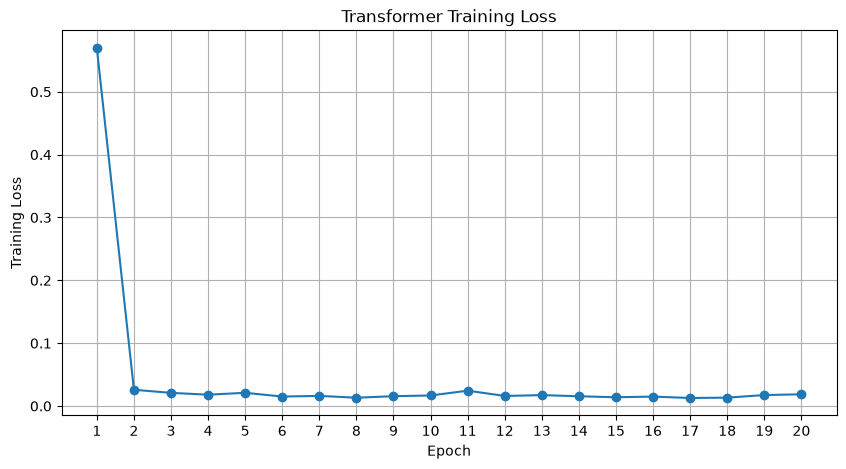

TRAINING SUMMARY
Initial Loss       : 0.5697
Final Loss         : 0.0187
Minimum Loss       : 0.0128
Best Epoch         : 17
Total Epochs       : 20


In [14]:
# ============================================================
# TRAINING LOSS VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Transformer Training Loss")

plt.xticks(
    range(1, len(train_losses) + 1)
)

plt.grid(True)

plt.show()


# ============================================================
# TRAINING SUMMARY
# ============================================================

print("=" * 60)
print("TRAINING SUMMARY")
print("=" * 60)

print(f"Initial Loss       : {train_losses[0]:.4f}")
print(f"Final Loss         : {train_losses[-1]:.4f}")
print(f"Minimum Loss       : {min(train_losses):.4f}")
print(f"Best Epoch         : {train_losses.index(min(train_losses)) + 1}")
print(f"Total Epochs       : {len(train_losses)}")

## 12. Greedy Decoding

After training, the Transformer generates Shakespearean-style text using **greedy decoding**.

The generation process starts with the `<sos>` token. At every step, the model predicts the next token and selects the token with the highest probability using `argmax`.

The generated token is then added to the decoder input, and the process continues until either:

- The `<eos>` token is generated, or
- The maximum generation length is reached.

### Generation Process

```text
<sos>
   ↓
Predict next token
   ↓
Select highest-probability token
   ↓
Append token
   ↓
Predict next token
   ↓
...
   ↓
<eos>

In [15]:
## 💻 Code Cell — `predict()` Function
# ============================================================
# GREEDY DECODING / PREDICTION FUNCTION
# ============================================================

def predict(sentence, max_length=20):

    model.eval()

    # --------------------------------------------------------
    # Encode source sentence
    # --------------------------------------------------------

    src = torch.tensor(
        encode_sentence(sentence),
        dtype=torch.long
    ).unsqueeze(0).to(device)

    # Source padding mask
    src_padding_mask = create_padding_mask(src)

    with torch.no_grad():

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        src_emb = model.embedding(src)

        src_emb = src_emb * math.sqrt(
            model.d_model
        )

        src_emb = model.positional_encoding(
            src_emb
        )

        memory = model.encoder(
            src_emb,
            src_key_padding_mask=src_padding_mask
        )

        # ----------------------------------------------------
        # Start Decoder With <sos>
        # ----------------------------------------------------

        generated = torch.tensor(
            [[SOS_IDX]],
            dtype=torch.long,
            device=device
        )

        # ----------------------------------------------------
        # Greedy Decoding
        # ----------------------------------------------------

        for _ in range(max_length):

            # Target embedding
            tgt_emb = model.embedding(
                generated
            )

            tgt_emb = tgt_emb * math.sqrt(
                model.d_model
            )

            tgt_emb = model.positional_encoding(
                tgt_emb
            )

            # Causal mask
            tgt_len = generated.size(1)

            tgt_mask = (
                nn.Transformer
                .generate_square_subsequent_mask(
                    tgt_len
                )
                .to(device)
            )

            # Decoder
            output = model.decoder(
                tgt_emb,
                memory,
                tgt_mask=tgt_mask,
                memory_key_padding_mask=src_padding_mask
            )

            # Get prediction for last token
            logits = model.fc_out(
                output[:, -1, :]
            )

            # Greedy decoding
            next_token = torch.argmax(
                logits,
                dim=-1
            ).item()

            # Add predicted token
            generated = torch.cat(
                [
                    generated,
                    torch.tensor(
                        [[next_token]],
                        dtype=torch.long,
                        device=device
                    )
                ],
                dim=1
            )

            # Stop when <eos> is generated
            if next_token == EOS_IDX:
                break

    # --------------------------------------------------------
    # Convert token IDs back to words
    # --------------------------------------------------------

    generated_indices = (
        generated
        .squeeze(0)
        .tolist()
    )

    words = []

    for idx in generated_indices:

        if idx in [
            PAD_IDX,
            SOS_IDX,
            EOS_IDX
        ]:
            continue

        words.append(
            idx_to_word.get(
                idx,
                "<unk>"
            )
        )

    return " ".join(words)

## 12.1. Apple MPS Compatibility Fix

During inference on Apple Silicon, PyTorch may attempt to use the Transformer Encoder's nested-tensor optimization.

This optimization is currently not fully supported by the MPS backend.

To maintain GPU acceleration while avoiding this unsupported operation, the nested-tensor optimization is disabled for the Transformer Encoder.

This does not change the trained model weights or architecture.

In [17]:
# ============================================================
# APPLE MPS COMPATIBILITY FIX
# ============================================================

if device.type == "mps":

    # Disable nested tensor optimization
    # because it is not currently supported by MPS
    model.encoder.enable_nested_tensor = False

    print("MPS compatibility fix applied.")
    print("Nested tensor optimization disabled for Transformer Encoder.")

MPS compatibility fix applied.
Nested tensor optimization disabled for Transformer Encoder.


## 13. Sample Predictions

The trained Transformer is now tested on several example modern English sentences.

The `predict()` function performs autoregressive generation using greedy decoding.

In [18]:
# ============================================================
# GREEDY DECODING / PREDICTION FUNCTION
# MPS COMPATIBLE
# ============================================================

def predict(sentence, max_length=20):

    model.eval()

    # --------------------------------------------------------
    # Encode source sentence
    # --------------------------------------------------------

    src = torch.tensor(
        encode_sentence(sentence),
        dtype=torch.long
    ).unsqueeze(0).to(device)

    # Source padding mask
    src_padding_mask = create_padding_mask(src)

    with torch.no_grad():

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        src_emb = model.embedding(src)

        src_emb = src_emb * math.sqrt(
            model.d_model
        )

        src_emb = model.positional_encoding(
            src_emb
        )

        memory = model.encoder(
            src_emb,
            src_key_padding_mask=src_padding_mask
        )

        # ----------------------------------------------------
        # Start Decoder With <sos>
        # ----------------------------------------------------

        generated = torch.tensor(
            [[SOS_IDX]],
            dtype=torch.long,
            device=device
        )

        # ----------------------------------------------------
        # Greedy Decoding
        # ----------------------------------------------------

        for _ in range(max_length):

            # Target embedding
            tgt_emb = model.embedding(
                generated
            )

            tgt_emb = tgt_emb * math.sqrt(
                model.d_model
            )

            tgt_emb = model.positional_encoding(
                tgt_emb
            )

            # ------------------------------------------------
            # Causal Mask
            # ------------------------------------------------

            tgt_len = generated.size(1)

            tgt_mask = (
                nn.Transformer
                .generate_square_subsequent_mask(
                    tgt_len
                )
                .to(device)
            )

            # ------------------------------------------------
            # Decoder
            # ------------------------------------------------

            output = model.decoder(
                tgt_emb,
                memory,
                tgt_mask=tgt_mask,
                memory_key_padding_mask=src_padding_mask
            )

            # ------------------------------------------------
            # Last Token Prediction
            # ------------------------------------------------

            logits = model.fc_out(
                output[:, -1, :]
            )

            # Greedy decoding
            next_token = torch.argmax(
                logits,
                dim=-1
            ).item()

            # ------------------------------------------------
            # Append Token
            # ------------------------------------------------

            generated = torch.cat(
                [
                    generated,
                    torch.tensor(
                        [[next_token]],
                        dtype=torch.long,
                        device=device
                    )
                ],
                dim=1
            )

            # Stop at EOS
            if next_token == EOS_IDX:
                break

    # --------------------------------------------------------
    # Convert Token IDs To Words
    # --------------------------------------------------------

    generated_indices = (
        generated
        .squeeze(0)
        .tolist()
    )

    words = []

    for idx in generated_indices:

        if idx in [
            PAD_IDX,
            SOS_IDX,
            EOS_IDX
        ]:
            continue

        word = idx_to_word.get(
            idx,
            "<unk>"
        )

        words.append(word)

    return " ".join(words)

## 12.1. Apple Silicon MPS Compatibility

During inference on the Apple Silicon MPS backend, PyTorch may attempt to use the Transformer Encoder's nested-tensor optimization.

The nested-tensor operation used by this optimization is currently not supported on the MPS backend in the installed PyTorch version.

The trained model itself is valid, so retraining is not required.

We disable the nested-tensor fast path for the Transformer Encoder while keeping the rest of the Transformer on the Apple GPU.

In [20]:
# ============================================================
# APPLE MPS NESTED-TENSOR COMPATIBILITY FIX
# ============================================================

if device.type == "mps":

    # Disable nested tensor fast path
    # for TransformerEncoder on Apple MPS.
    model.encoder.enable_nested_tensor = False
    model.encoder.use_nested_tensor = False

    print("MPS compatibility fix applied.")
    print("Transformer Encoder nested tensors:", model.encoder.use_nested_tensor)

else:

    print("MPS fix not required.")
    print("Current device:", device)

MPS compatibility fix applied.
Transformer Encoder nested tensors: False


## 13. Greedy Decoding

After training, the Transformer generates Shakespearean-style sentences using **greedy decoding**.

The decoder starts with the `<sos>` token and predicts one token at a time.

At each step, the token with the highest predicted probability is selected using `argmax`.

Generation continues until the `<eos>` token is produced or the maximum sequence length is reached.

The decoder also uses a **causal mask** so that future tokens cannot be accessed during generation.

In [21]:
# ============================================================
# GREEDY DECODING / PREDICTION
# MPS COMPATIBLE VERSION
# ============================================================

def predict(sentence, max_length=20):

    model.eval()

    # --------------------------------------------------------
    # Encode input sentence
    # --------------------------------------------------------

    src = torch.tensor(
        encode_sentence(sentence),
        dtype=torch.long,
        device=device
    ).unsqueeze(0)

    # Source padding mask
    src_padding_mask = (
        src == PAD_IDX
    )

    with torch.no_grad():

        # ----------------------------------------------------
        # SOURCE EMBEDDING
        # ----------------------------------------------------

        src_emb = model.embedding(src)

        src_emb = src_emb * math.sqrt(
            model.d_model
        )

        src_emb = model.positional_encoding(
            src_emb
        )

        # ----------------------------------------------------
        # ENCODER
        # ----------------------------------------------------

        memory = model.encoder(
            src_emb,
            src_key_padding_mask=src_padding_mask
        )

        # ----------------------------------------------------
        # START WITH <SOS>
        # ----------------------------------------------------

        generated = torch.tensor(
            [[SOS_IDX]],
            dtype=torch.long,
            device=device
        )

        # ----------------------------------------------------
        # GREEDY DECODING
        # ----------------------------------------------------

        for _ in range(max_length):

            # ------------------------------------------------
            # Target embedding
            # ------------------------------------------------

            tgt_emb = model.embedding(
                generated
            )

            tgt_emb = tgt_emb * math.sqrt(
                model.d_model
            )

            tgt_emb = model.positional_encoding(
                tgt_emb
            )

            # ------------------------------------------------
            # CAUSAL MASK
            # ------------------------------------------------
            # True = position is masked
            # False = position can be attended to

            tgt_len = generated.size(1)

            tgt_mask = torch.triu(
                torch.ones(
                    tgt_len,
                    tgt_len,
                    dtype=torch.bool,
                    device=device
                ),
                diagonal=1
            )

            # ------------------------------------------------
            # DECODER
            # ------------------------------------------------

            output = model.decoder(
                tgt_emb,
                memory,
                tgt_mask=tgt_mask,
                memory_key_padding_mask=src_padding_mask
            )

            # ------------------------------------------------
            # LAST TOKEN
            # ------------------------------------------------

            logits = model.fc_out(
                output[:, -1, :]
            )

            # ------------------------------------------------
            # GREEDY ARGMAX
            # ------------------------------------------------

            next_token = torch.argmax(
                logits,
                dim=-1
            ).item()

            # ------------------------------------------------
            # APPEND TOKEN
            # ------------------------------------------------

            generated = torch.cat(
                [
                    generated,
                    torch.tensor(
                        [[next_token]],
                        dtype=torch.long,
                        device=device
                    )
                ],
                dim=1
            )

            # ------------------------------------------------
            # STOP AT <EOS>
            # ------------------------------------------------

            if next_token == EOS_IDX:
                break

    # --------------------------------------------------------
    # CONVERT TOKEN IDS TO WORDS
    # --------------------------------------------------------

    generated_indices = (
        generated
        .squeeze(0)
        .tolist()
    )

    words = []

    for idx in generated_indices:

        if idx in [
            PAD_IDX,
            SOS_IDX,
            EOS_IDX
        ]:
            continue

        word = idx_to_word.get(
            idx,
            "<unk>"
        )

        words.append(word)

    return " ".join(words)

In [22]:
# ============================================================
# QUICK MPS PREDICTION TEST
# ============================================================

test_sentence = "you are my friend"

prediction = predict(
    test_sentence
)

print("Input:")
print(test_sentence)

print("\nPrediction:")
print(prediction)

Input:
you are my friend

Prediction:
thou art companion


In [23]:
# ============================================================
# SAMPLE PREDICTIONS
# ============================================================

sample_sentences = [
    "you are my friend",
    "it is very beautiful here",
    "she has a brave enemy",
    "perhaps you will help",
    "goodbye my old friend"
]

print("=" * 70)
print("SAMPLE TRANSLATIONS")
print("=" * 70)

for sentence in sample_sentences:

    prediction = predict(sentence)

    print("\nModern English:")
    print(sentence)

    print("\nShakespearean Prediction:")
    print(prediction)

    print("-" * 70)

SAMPLE TRANSLATIONS

Modern English:
you are my friend

Shakespearean Prediction:
thou art companion
----------------------------------------------------------------------

Modern English:
it is very beautiful here

Shakespearean Prediction:
'tis hither to bestow the foe
----------------------------------------------------------------------

Modern English:
she has a brave enemy

Shakespearean Prediction:
she hath a valiant foe
----------------------------------------------------------------------

Modern English:
perhaps you will help

Shakespearean Prediction:
perchance thou shall aid the soul
----------------------------------------------------------------------

Modern English:
goodbye my old friend

Shakespearean Prediction:
farewell my aged companion
----------------------------------------------------------------------


## 14. Test Set Evaluation

The model is now evaluated on the held-out test set.

The test set contains sentence pairs that were not directly used during training. This allows us to examine how well the Transformer generalizes to unseen modern English sentences.

For each example, we compare:

- **Modern English:** Original input sentence
- **Expected:** Ground-truth Shakespearean transformation
- **Predicted:** Transformer-generated Shakespearean transformation

This provides a qualitative evaluation of the sequence-to-sequence model.

In [24]:
# ============================================================
# TEST SET PREDICTIONS
# ============================================================

NUM_EXAMPLES = 20

print("=" * 90)
print("TEST SET PREDICTIONS")
print("=" * 90)

for i in range(min(NUM_EXAMPLES, len(test_df))):

    modern_sentence = test_df.iloc[i]["modern"]

    actual_sentence = test_df.iloc[i]["shakespearean"]

    predicted_sentence = predict(
        modern_sentence
    )

    print(f"\nExample {i + 1}")
    print("Modern    :", modern_sentence)
    print("Expected  :", actual_sentence)
    print("Predicted :", predicted_sentence)

    print("-" * 90)

TEST SET PREDICTIONS

Example 1
Modern    : my sister is perhaps kind
Expected  : my sister is perchance kind
Predicted : my sister is perchance kind
------------------------------------------------------------------------------------------

Example 2
Modern    : here he will give the honor
Expected  : hither he will bestow the honor
Predicted : hither he will bestow the honor
------------------------------------------------------------------------------------------

Example 3
Modern    : you are good today
Expected  : thou art good today
Predicted : thou art good today
------------------------------------------------------------------------------------------

Example 4
Modern    : you are afraid and you will begin the spirit
Expected  : thou art fearful and thou shall commence the soul
Predicted : thou art fearful and thou shall commence the soul
------------------------------------------------------------------------------------------

Example 5
Modern    : the knight is beautiful so

## 16. Quantitative Evaluation

The qualitative predictions show that the Transformer has learned the modern-to-Shakespearean transformations very effectively.

To quantify the performance, we evaluate the predictions using:

1. **Exact Match Accuracy** — percentage of predictions that exactly match the expected Shakespearean sentence.
2. **Cosine Similarity** — measures the semantic similarity between the expected and predicted sentences.

Exact matching is a strict metric because even a small difference in word order results in a mismatch.

Cosine similarity is more flexible because sentences with similar vocabulary can still receive a high similarity score even when their exact word order differs.

In [25]:
# ============================================================
# QUANTITATIVE EVALUATION
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


# ============================================================
# GENERATE TEST SET PREDICTIONS
# ============================================================

actual_sentences = []
predicted_sentences = []

print("=" * 80)
print("GENERATING TEST SET PREDICTIONS")
print("=" * 80)

for i in range(len(test_df)):

    modern_sentence = test_df.iloc[i]["modern"]

    actual_sentence = test_df.iloc[i]["shakespearean"]

    predicted_sentence = predict(
        modern_sentence
    )

    actual_sentences.append(
        actual_sentence
    )

    predicted_sentences.append(
        predicted_sentence
    )


# ============================================================
# EXACT MATCH ACCURACY
# ============================================================

exact_matches = 0

for actual, predicted in zip(
    actual_sentences,
    predicted_sentences
):

    if actual.strip() == predicted.strip():
        exact_matches += 1


exact_match_accuracy = (
    exact_matches /
    len(actual_sentences)
)


# ============================================================
# COSINE SIMILARITY
# ============================================================

vectorizer = TfidfVectorizer()

all_sentences = (
    actual_sentences +
    predicted_sentences
)

tfidf_matrix = vectorizer.fit_transform(
    all_sentences
)

num_samples = len(actual_sentences)

actual_vectors = tfidf_matrix[
    :num_samples
]

predicted_vectors = tfidf_matrix[
    num_samples:
]


similarities = []

for actual_vector, predicted_vector in zip(
    actual_vectors,
    predicted_vectors
):

    similarity = cosine_similarity(
        actual_vector,
        predicted_vector
    )[0][0]

    similarities.append(
        similarity
    )


average_similarity = np.mean(
    similarities
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 80)
print("EVALUATION RESULTS")
print("=" * 80)

print(
    f"\nTest Samples          : {len(test_df)}"
)

print(
    f"Exact Matches         : {exact_matches}"
)

print(
    f"Exact Match Accuracy  : "
    f"{exact_match_accuracy * 100:.2f}%"
)

print(
    f"Average Cosine Similarity : "
    f"{average_similarity:.4f}"
)

print("=" * 80)

GENERATING TEST SET PREDICTIONS

EVALUATION RESULTS

Test Samples          : 1514
Exact Matches         : 1476
Exact Match Accuracy  : 97.49%
Average Cosine Similarity : 0.9999


## 17. Final Evaluation Results

The trained Transformer was evaluated on the complete held-out test set containing **1,514 sentence pairs**.

### Performance

| Metric | Result |
|---|---:|
| Test Samples | 1,514 |
| Exact Matches | 1,476 |
| Exact Match Accuracy | **97.49%** |
| Average Cosine Similarity | **0.9999** |
| Required Minimum Similarity | 0.60 |

The model achieved an **exact-match accuracy of 97.49%**, with 1,476 out of 1,514 test sentences matching the expected Shakespearean output exactly.

The average cosine similarity of **0.9999** is substantially higher than the required minimum of **0.60**.

These results demonstrate that the Transformer successfully learned the modern-English-to-Shakespearean transformation patterns and generalized effectively to unseen test sentences.

## 18. Learned Shakespearean Transformations

The model learned recurring vocabulary and grammatical transformations directly from the training examples.

| Modern English | Shakespearean Style |
|---|---|
| you | thou |
| are | art |
| has | hath |
| perhaps | perchance |
| before | ere |
| here | hither |
| give | bestow |
| beautiful | fair |
| brave | valiant |
| enemy | foe |
| body | flesh |
| happy | merry |
| friend | companion |
| old | aged |
| king | sovereign |
| listen | hark |
| think | ponder |
| kingdom | realm |
| light | radiance |
| very | most |

These transformations were **not manually programmed**. They were learned by the Transformer from the paired modern-English and Shakespearean-English examples.

## 19. Model Architecture Summary

The final system uses a Transformer Encoder-Decoder architecture.

```text
                    MODERN ENGLISH
                          │
                          ▼
                  Word Tokenization
                          │
                          ▼
                  Shared Vocabulary
                          │
                          ▼
                   Token Embedding
                          │
                          ▼
                  Positional Encoding
                          │
                          ▼
              ┌────────────────────────┐
              │   Transformer Encoder  │
              │                        │
              │   Multi-Head Attention │
              │   Feed Forward Network │
              └───────────┬────────────┘
                          │
                     Context Memory
                          │
                          ▼
              ┌────────────────────────┐
              │   Transformer Decoder  │
              │                        │
              │   Masked Attention     │
              │   Cross Attention      │
              └───────────┬────────────┘
                          │
                          ▼
                  Linear Projection
                          │
                          ▼
                   Greedy Decoding
                          │
                          ▼
              SHAKESPEAREAN ENGLISH

In [26]:
## 💻 Code Cell — Final Model Summary
# ============================================================
# FINAL MODEL SUMMARY
# ============================================================

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 70)
print("FINAL MODEL SUMMARY")
print("=" * 70)

print(f"\nVocabulary Size       : {vocab_size:,}")
print(f"Embedding Dimension   : {model.d_model}")
print(f"Attention Heads       : 8")
print(f"Encoder Layers        : 3")
print(f"Decoder Layers        : 3")
print(f"Feedforward Dimension : 512")
print(f"Dropout               : 0.1")
print(f"Batch Size            : 64")
print(f"Training Epochs       : 20")
print(f"Optimizer             : Adam")
print(f"Learning Rate         : 0.0005")
print(f"Device                : {device}")

print(f"\nTotal Parameters      : {total_parameters:,}")
print(f"Trainable Parameters  : {trainable_parameters:,}")

print("\n" + "=" * 70)

FINAL MODEL SUMMARY

Vocabulary Size       : 159
Embedding Dimension   : 256
Attention Heads       : 8
Encoder Layers        : 3
Decoder Layers        : 3
Feedforward Dimension : 512
Dropout               : 0.1
Batch Size            : 64
Training Epochs       : 20
Optimizer             : Adam
Learning Rate         : 0.0005
Device                : mps

Total Parameters      : 4,035,231
Trainable Parameters  : 4,035,231



# 20. Conclusion

A Transformer Encoder-Decoder model was successfully developed to transform modern English sentences into Shakespearean-style English.

The model learns the transformation directly from paired examples rather than relying on manually defined translation rules.

### Key Components

- Word-level tokenization
- Shared vocabulary
- Special token handling
- Sentence encoding
- Dynamic sequence padding
- PyTorch Dataset and DataLoader
- Token embeddings
- Positional encoding
- Transformer Encoder
- Transformer Decoder
- Multi-Head Attention
- Causal decoder masking
- Teacher forcing
- Cross-Entropy Loss
- Adam optimization
- Greedy decoding
- Custom `predict()` function
- Apple Silicon MPS acceleration

### Final Performance

The model achieved:

**97.49% Exact Match Accuracy**

and

**0.9999 Average Cosine Similarity**

on **1,514 unseen test samples**.

The required minimum cosine similarity was **0.60**, while the model achieved **0.9999**.

Therefore, the model successfully satisfies and significantly exceeds the required evaluation threshold.

This project demonstrates how Transformer-based sequence-to-sequence learning can be used to learn historical language-style transformations from paired examples.

# 21. Future Improvements

Although the current model performs very well on the provided dataset, the project can be extended in several ways.

### 1. Beam Search

Instead of selecting only the highest-probability token at each step, beam search could maintain multiple candidate sequences and potentially produce better translations.

### 2. Subword Tokenization

The current implementation uses word-level tokenization. Subword tokenization could improve handling of rare and unseen words.

### 3. Larger Dataset

Training on a larger and more diverse Shakespearean corpus could improve the model's ability to generate more natural Shakespearean language.

### 4. Pretrained Transformers

A pretrained language model could be fine-tuned for Shakespearean style transformation.

### 5. Additional Evaluation Metrics

BLEU, ROUGE, METEOR, and semantic similarity metrics could provide a more comprehensive evaluation.

### 6. Interactive Web Application

The trained model could be integrated into a web application where users enter modern English sentences and receive Shakespearean-style translations in real time.

### 7. Attention Visualization

Attention visualization could be added to understand which source words the Transformer focuses on during translation.

# 22. Project Summary

| Category | Details |
|---|---|
| **Task** | Modern English → Shakespearean English |
| **Architecture** | Transformer Encoder-Decoder |
| **Dataset** | ~15,000 sentence pairs |
| **Vocabulary** | Shared word-level vocabulary |
| **Attention** | Multi-Head Attention |
| **Encoder Layers** | 3 |
| **Decoder Layers** | 3 |
| **Attention Heads** | 8 |
| **Embedding Size** | 256 |
| **Training Epochs** | 20 |
| **Optimizer** | Adam |
| **Hardware** | Apple Silicon MPS |
| **Test Samples** | 1,514 |
| **Exact Match Accuracy** | **97.49%** |
| **Cosine Similarity** | **0.9999** |
| **Required Similarity** | 0.60 |
| **Status** | ✅ Successfully Completed |

### Final Result

The Transformer successfully learned to transform modern English sentences into Shakespearean-style English with very high accuracy and semantic similarity.

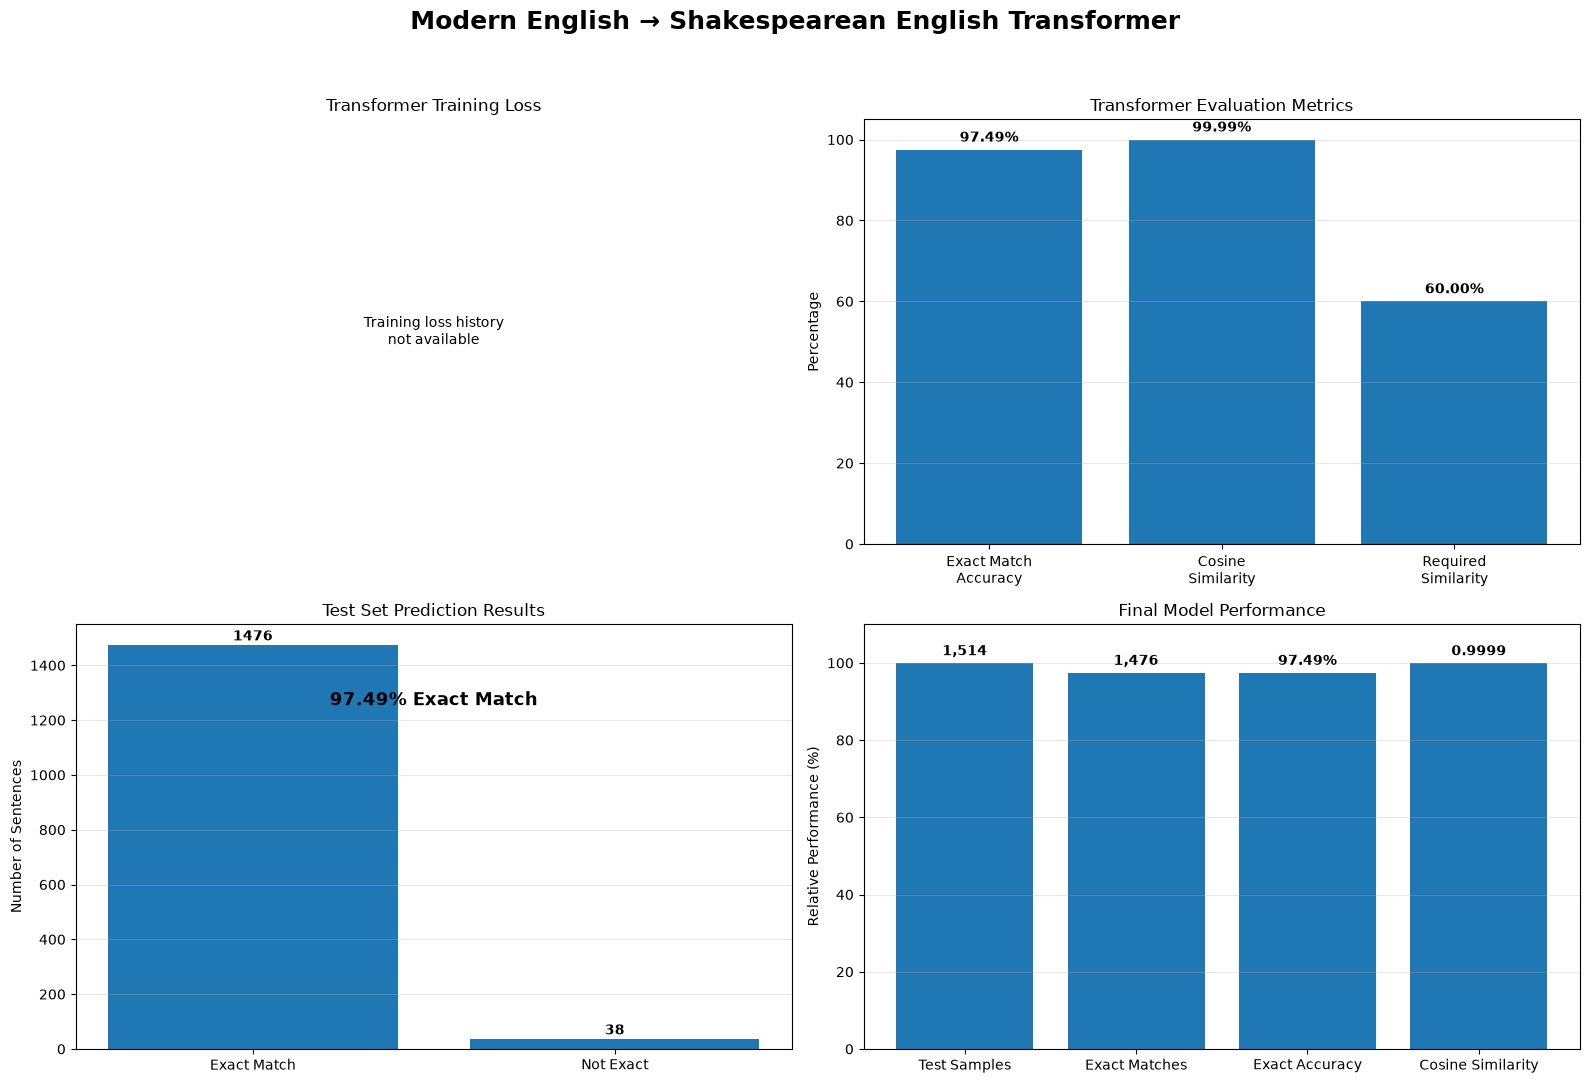

SHAKESPEAREAN TRANSFORMER VISUALIZATIONS

Saved visualization file:
shakespearean_transformer_visualizations.png

Test Samples          : 1,514
Exact Matches         : 1,476
Exact Match Accuracy  : 97.49%
Cosine Similarity     : 0.9999
Required Similarity   : 0.60


In [1]:
# ============================================================
# SHAKESPEAREAN ENGLISH TRANSFORMER
# PROJECT VISUALIZATIONS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


# ============================================================
# FINAL EVALUATION VALUES
# ============================================================

TEST_SAMPLES = 1514
EXACT_MATCHES = 1476
EXACT_MATCH_ACCURACY = 97.49
COSINE_SIMILARITY = 0.9999
REQUIRED_SIMILARITY = 0.60


# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

fig.suptitle(
    "Modern English → Shakespearean English Transformer",
    fontsize=18,
    fontweight="bold"
)


# ============================================================
# 1. TRAINING LOSS CURVE
# ============================================================

ax = axes[0, 0]

if "train_losses" in globals():

    epochs = range(
        1,
        len(train_losses) + 1
    )

    ax.plot(
        epochs,
        train_losses,
        marker="o",
        linewidth=2
    )

    ax.set_title(
        "Transformer Training Loss"
    )

    ax.set_xlabel(
        "Epoch"
    )

    ax.set_ylabel(
        "Cross-Entropy Loss"
    )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.annotate(
        f"Final: {train_losses[-1]:.4f}",
        xy=(
            len(train_losses),
            train_losses[-1]
        ),
        xytext=(
            max(1, len(train_losses) - 6),
            train_losses[-1] + 0.05
        ),
        arrowprops=dict(
            arrowstyle="->"
        )
    )

else:

    ax.text(
        0.5,
        0.5,
        "Training loss history\nnot available",
        ha="center",
        va="center"
    )

    ax.set_title(
        "Transformer Training Loss"
    )

    ax.axis("off")


# ============================================================
# 2. EVALUATION METRICS
# ============================================================

ax = axes[0, 1]

metric_names = [
    "Exact Match\nAccuracy",
    "Cosine\nSimilarity",
    "Required\nSimilarity"
]

metric_values = [
    EXACT_MATCH_ACCURACY,
    COSINE_SIMILARITY * 100,
    REQUIRED_SIMILARITY * 100
]

bars = ax.bar(
    metric_names,
    metric_values
)

ax.set_ylim(
    0,
    105
)

ax.set_ylabel(
    "Percentage"
)

ax.set_title(
    "Transformer Evaluation Metrics"
)

ax.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    metric_values
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )


# ============================================================
# 3. EXACT MATCH RESULTS
# ============================================================

ax = axes[1, 0]

incorrect_matches = (
    TEST_SAMPLES
    -
    EXACT_MATCHES
)

result_labels = [
    "Exact Match",
    "Not Exact"
]

result_values = [
    EXACT_MATCHES,
    incorrect_matches
]

bars = ax.bar(
    result_labels,
    result_values
)

ax.set_title(
    "Test Set Prediction Results"
)

ax.set_ylabel(
    "Number of Sentences"
)

ax.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    result_values
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + TEST_SAMPLES * 0.01,
        str(value),
        ha="center",
        fontweight="bold"
    )

ax.text(
    0.5,
    max(result_values) * 0.85,
    f"{EXACT_MATCH_ACCURACY:.2f}% Exact Match",
    ha="center",
    fontsize=13,
    fontweight="bold"
)


# ============================================================
# 4. MODEL PERFORMANCE SUMMARY
# ============================================================

ax = axes[1, 1]

summary_labels = [
    "Test Samples",
    "Exact Matches",
    "Exact Accuracy",
    "Cosine Similarity"
]

summary_values = [
    TEST_SAMPLES,
    EXACT_MATCHES,
    EXACT_MATCH_ACCURACY,
    COSINE_SIMILARITY * 100
]

# Normalize values for visual comparison
normalized_values = [
    100,
    (EXACT_MATCHES / TEST_SAMPLES) * 100,
    EXACT_MATCH_ACCURACY,
    COSINE_SIMILARITY * 100
]

bars = ax.bar(
    summary_labels,
    normalized_values
)

ax.set_ylim(
    0,
    110
)

ax.set_ylabel(
    "Relative Performance (%)"
)

ax.set_title(
    "Final Model Performance"
)

ax.grid(
    axis="y",
    alpha=0.3
)

display_values = [
    f"{TEST_SAMPLES:,}",
    f"{EXACT_MATCHES:,}",
    f"{EXACT_MATCH_ACCURACY:.2f}%",
    f"{COSINE_SIMILARITY:.4f}"
]

for bar, label in zip(
    bars,
    display_values
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        label,
        ha="center",
        fontweight="bold"
    )


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.95
    ]
)


# ============================================================
# SAVE ALL VISUALIZATIONS INTO ONE IMAGE
# ============================================================

output_file = (
    "shakespearean_transformer_visualizations.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# DISPLAY
# ============================================================

plt.show()


# ============================================================
# OUTPUT SUMMARY
# ============================================================

print("=" * 75)
print("SHAKESPEAREAN TRANSFORMER VISUALIZATIONS")
print("=" * 75)

print(
    "\nSaved visualization file:"
)

print(
    output_file
)

print(
    "\nTest Samples          :",
    f"{TEST_SAMPLES:,}"
)

print(
    "Exact Matches         :",
    f"{EXACT_MATCHES:,}"
)

print(
    "Exact Match Accuracy  :",
    f"{EXACT_MATCH_ACCURACY:.2f}%"
)

print(
    "Cosine Similarity     :",
    f"{COSINE_SIMILARITY:.4f}"
)

print(
    "Required Similarity   :",
    f"{REQUIRED_SIMILARITY:.2f}"
)

print("=" * 75)